# Practicum 1 (версия 2). Анализ продаж в pandas

Улучшенная версия ноутбука после ревью AI-ассистента: тот же датасет
`transactions.csv` (1 008 688 строк, 01.09.2017 – 31.10.2019) и та же
последовательность шагов, но код переписан — вынесены функции, собраны
константы, добавлены проверки корректности.

**Что изменилось по сравнению с `practicum1.ipynb`:**

* все «магические числа» собраны в блок констант в начале;
* расчёты возвращают `DataFrame`, печать вынесена отдельно;
* ABC-XYZ считается **один раз** и переиспользуется в шагах 12–16
  (в версии 1 тот же расчёт выполнялся 4 раза);
* добавлены `docstring`, аннотации типов и проверки (`check`);
* периоды `PERIOD_START`/`PERIOD_END` заданы явно и одинаково во всех шагах;
* экспорт CSV идёт через `save_csv` с кодировкой `utf-8-sig` и обратным чтением.


## Ревью версии 1 и что исправлено

**Оценка кода версии 1.** Логика шагов верная и воспроизводимая, но есть
системные замечания по стилю и архитектуре: код писался «потоком», поэтому
одни и те же операции повторяются, числа-константы разбросаны по ячейкам, а
переменные переиспользуются так, что за данными становится трудно следить.

| # | Замечание к версии 1 | Что сделано в версии 2 |
|---|---|---|
| 1 | ABC-XYZ считался 4 раза (шаги 12, 13 и три запуска в 15) — десятки секунд впустую | Считается один раз: `items_full = abc_xyz_analysis(df)`, дальше шаги 12–14 берут из него срезы, шаг 15 считает только период |
| 2 | Магические числа по всему коду: 80/95, 15/25, 2000/500000, 100 000, 0,995 | Блок констант `ABC_THRESHOLD_A`, `XYZ_CV_X`, `EXTREME_MIN_QUANTITY`, `PLOT_SAMPLE_SIZE` и т. д. |
| 3 | Шаг 10 молча перезаписывал `df`, и все следующие шаги работали уже с другим набором строк | `df_raw = load_data()` + `df = add_price(df_raw)`; функция сама сообщает, сколько строк удалила |
| 4 | Проверок корректности не было вообще | `check()`: сумма по клиентам равна сумме по транзакциям, топ отсортирован по убыванию, доли групп дают 100 % |
| 5 | Функции (`get_top_products`, `abc_xyz_analysis`) печатали результат вместо возврата | Все расчётные функции возвращают `DataFrame`, печать — отдельными `print`/`display` |
| 6 | Нет `docstring` и аннотаций типов | Добавлены краткие `docstring` и hints (`-> pd.DataFrame`, `n: int`) |
| 7 | Таблица `xyz` собиралась через `.values` из четырёх разных Series — хрупко | Собирается `DataFrame` по индексу `pivot` и мержится по `item` |
| 8 | В одном коде смешаны `print(...to_string())`, `df.head()` и ручное форматирование | `display()` для таблиц, `fmt_int`/`fmt_money`/`fmt_pct` только для чисел в тексте |
| 9 | Разные границы «последних 6 месяцев»: 30.04 в шаге 6 и 01.05 в шаге 15 | Единые `PERIOD_START`/`PERIOD_END`; расчёт `end_date − 6 месяцев` показан отдельно как проверка |
| 10 | `to_csv` без кодировки и без проверки результата | `save_csv(..., encoding="utf-8-sig")` + обратное чтение и сверка колонок |
| 11 | `object`-колонки `client`/`item` на 1 млн строк | `astype("category")`: меньше памяти и быстрее `groupby` |
| 12 | `groupby` без `observed=True` на категориальных данных | Явный `observed=True`, чтобы не появлялись пустые комбинации |
| 13 | Колонка называлась `group` — тень для `DataFrame.groupby` | Явные имена `abc_group`, `xyz_group`, `abc_xyz` |
| 14 | Русские имена колонок (`товаров`, `выручка`) вперемешку с английскими | Английские имена в данных, русский — только в подписях и `docstring` |

**Что оставлено без изменений:** `np.select` для групп, подвыборка 100 000
строк для KDE, обрезка оси по 99,5-му процентилю и `showfliers=False` в
boxplot — это корректные решения для миллиона строк, они лишь вынесены в
константы и объяснены комментариями.


### Конфигурация анализа

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- настройки анализа в одном месте ---
DATA_PATH = Path("transactions.csv")
REQUIRED_COLUMNS = ["tr_date", "tcode", "client", "item", "item_group", "quantity", "amount"]

ABC_THRESHOLD_A = 80.0      # верхняя граница накопленной доли выручки для группы A, %
ABC_THRESHOLD_B = 95.0      # верхняя граница для группы B, %
XYZ_CV_X = 15.0             # X: CV < 15 %
XYZ_CV_Y = 25.0             # Y: 15 % <= CV <= 25 %

EXTREME_MIN_QUANTITY = 2_000      # «много штук» для клиента-экстремума
EXTREME_MIN_AMOUNT = 500_000      # «большая сумма» для клиента-экстремума

PERIOD_START = "2019-05-01"       # последние 6 календарных месяцев
PERIOD_END = "2019-10-31"

PLOT_SAMPLE_SIZE = 100_000        # подвыборка для KDE: на 1 млн точек не хватит памяти
PLOT_QUANTILE = 0.995             # обрезка оси X, чтобы хвост не сжимал гистограмму

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")


def fmt_int(value: float) -> str:
    # 1 008 688
    return f"{value:,.0f}".replace(",", " ")


def fmt_money(value: float) -> str:
    # 1 234,56
    return f"{value:,.2f}".replace(",", " ").replace(".", ",")


def fmt_pct(value: float) -> str:
    # 12,34 %
    return f"{value:.2f}".replace(".", ",") + " %"


def check(condition: bool, message: str) -> None:
    # дешёвая замена assert: срабатывает и при запуске с -O
    if not condition:
        raise AssertionError(message)


### Подготовка: загрузка, цена и фильтр по периоду

Функции загрузки и подготовки — то, что в версии 1 было размазано по ячейкам
1, 6 и 10. `load_data` проверяет схему файла и типы, `add_price` убирает
строки с нулевым количеством, `filter_period` фильтрует по датам.

In [2]:
def load_data(path: Path = DATA_PATH) -> pd.DataFrame:
    # читает CSV, проверяет схему, приводит дату и категориальные колонки
    if not path.exists():
        raise FileNotFoundError(f"Не найден {path.resolve()} — положите transactions.csv рядом с ноутбуком")

    df = pd.read_csv(path)
    missing = [col for col in REQUIRED_COLUMNS if col not in df.columns]
    if missing:
        raise ValueError(f"В файле нет обязательных колонок: {missing}")

    df["tr_date"] = pd.to_datetime(df["tr_date"], errors="coerce")
    bad_dates = int(df["tr_date"].isna().sum())
    if bad_dates:
        print(f"Внимание: {bad_dates} значений даты не разобрано (стали NaT)")

    # category вместо object: 1 млн строк, меньше памяти и быстрее groupby
    for col in ["tcode", "client", "item", "item_group"]:
        df[col] = df[col].astype("category")
    return df


def add_price(df: pd.DataFrame) -> pd.DataFrame:
    # price = amount / quantity; строки с quantity = 0 убираем (деление на ноль)
    zero_quantity = df[df["quantity"] == 0]
    if not zero_quantity.empty:
        print(f"Удаляю строк с quantity = 0: {len(zero_quantity)}")
        print(zero_quantity.to_string())

    result = df[df["quantity"] != 0].copy()
    result["price"] = result["amount"] / result["quantity"]
    return result


def filter_period(df: pd.DataFrame, start: str, end: str) -> pd.DataFrame:
    # строки за период [start, end] включительно
    start_ts, end_ts = pd.Timestamp(start), pd.Timestamp(end)
    if start_ts > end_ts:
        raise ValueError(f"start={start} позже end={end}")
    mask = (df["tr_date"] >= start_ts) & (df["tr_date"] <= end_ts)
    return df.loc[mask].copy()


## Шаг 1. Загрузка CSV в DataFrame

**Промпт к AI-ассистенту:**

> напиши код на питоне для загрузки csv файла "transactions.csv" в DataFrame
> при помощи pandas. Датасет содержит транзакции продаж с колонками:
> tr_date, tcode, client, item, item_group, quantity, amount. Убедись что
> колонка Date преобразована в тип datetime. Выведи первые 5 строк и
> основную информацию о датасете

Загрузка вынесена в `load_data`: проверка схемы, приведение даты и
`category`-типы для строковых колонок.

In [3]:
df_raw = load_data()
df = df_raw.copy()

print(f"Строк: {fmt_int(len(df))}, столбцов: {df.shape[1]}")
print("Первые 5 строк:")
display(df.head(5))

print("\nИнформация о датасете:")
df.info()


Строк: 1 008 688, столбцов: 7
Первые 5 строк:
     tr_date          tcode       client      item                    item_group  quantity  amount
0 2017-09-01  code000000001  client13166   sku8444              Скобяные изделия         1      29
1 2017-09-01  code000000001  client13166  sku12545  Оборудование для сада и дачи         1     329
2 2017-09-01  code000000001  client13166   sku3391                   Инструменты         1     169
3 2017-09-01  code000000001  client13166  sku20444                   Инструменты         2     578
4 2017-09-01  code000000002   client1239  sku29959              Скобяные изделия         1     329

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 1008688 entries, 0 to 1008687
Data columns (total 7 columns):
 #   Column      Non-Null Count    Dtype         
---  ------      --------------    -----         
 0   tr_date     1008688 non-null  datetime64[us]
 1   tcode       1008688 non-null  category      
 2   client      1008688 non-null  

## Шаг 2. Статистический анализ датасета

**Промпт к AI-ассистенту:**

> Проведи статистический анализ DataFrame с продажами: 1. Выведи общую
> информацию: количество строк, столбцов, типы данных 2. Рассчитай
> описательную статистику для всех числовых колонок (quantity, amount):
> min, max, mean, std, median, 25%, 75% 3. Проверь наличие пропущенных
> значений 4. Для каждого числового столбца выведи уникальных значений и их
> диапазоны

In [4]:
numeric_cols = ["quantity", "amount"]

stats = pd.DataFrame(
    {
        col: {
            "count": df[col].count(),
            "min": df[col].min(),
            "25%": df[col].quantile(0.25),
            "median (50%)": df[col].median(),
            "75%": df[col].quantile(0.75),
            "max": df[col].max(),
            "mean": df[col].mean(),
            "std": df[col].std(),
        }
        for col in numeric_cols
    }
)
print("Описательная статистика:")
display(stats.round(2))

print("Пропуски по колонкам:")
display(df.isna().sum().rename("пропусков").to_frame().T)

print("Уникальные значения и диапазоны:")
for col in numeric_cols:
    series = df[col]
    print(
        f"  {col}: уникальных {series.nunique()}, "
        f"диапазон {fmt_int(series.min())} – {fmt_int(series.max())}, "
        f"нулей {int((series == 0).sum())}"
    )


Описательная статистика:
                quantity      amount
count         1008688.00  1008688.00
min                 0.00        0.00
25%                 1.00       56.00
median (50%)        1.00      150.00
75%                 2.00      425.00
max              1100.00   213177.00
mean                2.22      623.19
std                 5.03     1878.42
Пропуски по колонкам:
           tr_date  tcode  client  item  item_group  quantity  amount
пропусков        0      0       0     0           0         0       0
Уникальные значения и диапазоны:
  quantity: уникальных 198, диапазон 0 – 1 100, нулей 1
  amount: уникальных 11181, диапазон 0 – 213 177, нулей 17


## Шаг 3. Распределения quantity и amount

**Промпт к AI-ассистенту:**

> Создай графики для анализа распределения quantity и amount из DataFrame df.
> Используй sns.histplot с kde=True и sns.boxplot. Сделай два окна: одно с
> гистограммами, второе с box plot.

Отрисовка вынесена в переиспользуемый `plot_histogram`, а доля выбросов для
подписи считается функцией `outlier_share`.

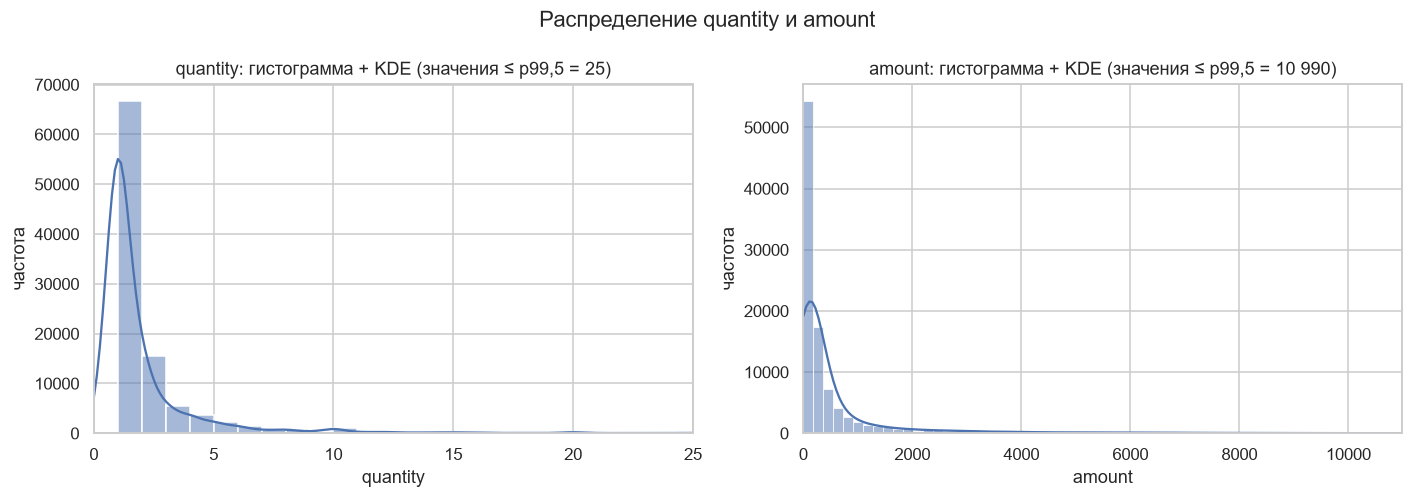

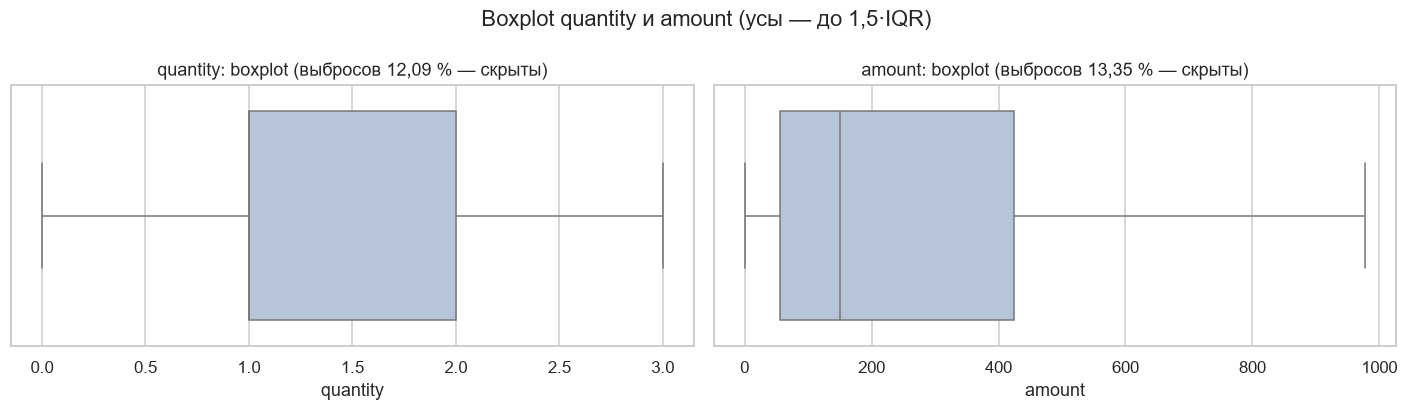

In [5]:
def plot_histogram(ax, series: pd.Series, *, bins=60, xlim=None, xlabel="") -> None:
    # гистограмма + KDE; подвыборка и обрезка хвоста — из констант конфига
    data = series.dropna()
    if len(data) > PLOT_SAMPLE_SIZE:
        data = data.sample(PLOT_SAMPLE_SIZE, random_state=42)
    if xlim is not None:
        data = data[data <= xlim]

    sns.histplot(x=data, kde=True, bins=bins, kde_kws={"bw_adjust": 2.0}, ax=ax)
    if xlim is not None:
        ax.set_xlim(0, xlim)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("частота")


def outlier_share(series: pd.Series) -> float:
    # доля значений за верхней границей 1,5·IQR — для подписи под boxplot
    q1, q3 = series.quantile([0.25, 0.75])
    return float((series > q3 + 1.5 * (q3 - q1)).mean())


def choose_bins(series: pd.Series, upper: float):
    # для целых величин с малым диапазоном шаг бина 1, иначе 60 бинов
    if upper <= 100 and bool((series % 1 == 0).all()):
        return np.arange(0, upper + 1)
    return np.linspace(0, upper, 61)


# окно 1 — гистограммы с KDE
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col in zip(axes, ["quantity", "amount"]):
    upper = df[col].quantile(PLOT_QUANTILE)
    data = df[col][df[col] <= upper]
    plot_histogram(ax, df[col], bins=choose_bins(data, upper), xlim=upper, xlabel=col)
    ax.set_title(f"{col}: гистограмма + KDE (значения ≤ p99,5 = {fmt_int(upper)})")
fig.suptitle("Распределение quantity и amount")
fig.tight_layout()
plt.show()

# окно 2 — boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ["quantity", "amount"]):
    sns.boxplot(x=df[col], ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_title(f"{col}: boxplot (выбросов {fmt_pct(outlier_share(df[col]) * 100)} — скрыты)")
    ax.set_xlabel(col)
fig.suptitle("Boxplot quantity и amount (усы — до 1,5·IQR)")
fig.tight_layout()
plt.show()


## Шаг 4. ТОП-5 товаров по сумме продаж

**Промпт к AI-ассистенту:**

> На основе DataFrame с продажами: 1. Сгруппируй данные по колонке item
> (товар) 2. Для каждого товара рассчитай сумму двух метрик: - Кол-во:
> sum(quantity) - Сумма продаж: sum(amount) 3. Отсортируй результат по сумме
> продаж в убывающем порядке 4. Выведи только ТОП-5 товаров с самыми
> большими продажами 5. Сохрани результат в переменную 'top_5_products'

In [6]:
top_products = (
    df.groupby("item", observed=True, as_index=False)
    .agg(
        quantity=("quantity", "sum"),
        amount=("amount", "sum"),
    )
    .sort_values("amount", ascending=False)
    .head(5)
    .reset_index(drop=True)
)
top_5_products = top_products.copy()   # имя из задания

check(top_products["amount"].is_monotonic_decreasing, "ТОП не отсортирован по убыванию")
print("ТОП-5 товаров по сумме продаж:")
display(top_products)
print(f"Доля ТОП-5 в выручке: {fmt_pct(top_5_products['amount'].sum() / df['amount'].sum() * 100)}")


ТОП-5 товаров по сумме продаж:
       item  quantity   amount
0  sku26161     18902  5373638
1  sku18199      7250  3951361
2  sku21947     15304  3918570
3  sku28128      7705  3027786
4   sku8342      3512  2113158
Доля ТОП-5 в выручке: 2,92 %


## Шаг 5. Функция get_top_products(df, n=5)

**Промпт к AI-ассистенту:**

> Переделай предыдущий код так, чтобы число ТОП товаров было параметром
> (переменной N). Создай функцию get_top_products(df, n=5), которая:
> 1. Принимает DataFrame df и параметр n (количество товаров) 2. Выполняет
> группировку, сортировку и фильтрацию как в предыдущем примере 3. Возвращает
> DataFrame с n лучшими товарами Протестируй функцию с разными значениями N:
> - N = 5 - N = 10

В версии 2 функция не печатает, а возвращает результат, проверяет `n` и
контролирует число строк — её же используют шаги 4, 6 и 16.

In [7]:
def get_top_products(df: pd.DataFrame, n: int = 5) -> pd.DataFrame:
    """Возвращает n товаров с наибольшей суммой продаж.

    Колонки результата: item, quantity (сумма штук), amount (сумма продаж).
    """
    if n <= 0:
        raise ValueError(f"n должно быть положительным, получено n={n}")

    result = (
        df.groupby("item", observed=True, as_index=False)
        .agg(quantity=("quantity", "sum"), amount=("amount", "sum"))
        .sort_values("amount", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )
    check(len(result) == min(n, df["item"].nunique()), "вернулось неверное число товаров")
    return result


for n in (5, 10):
    print(f"ТОП-{n}:")
    display(get_top_products(df, n))


ТОП-5:
       item  quantity   amount
0  sku26161     18902  5373638
1  sku18199      7250  3951361
2  sku21947     15304  3918570
3  sku28128      7705  3027786
4   sku8342      3512  2113158
ТОП-10:
       item  quantity   amount
0  sku26161     18902  5373638
1  sku18199      7250  3951361
2  sku21947     15304  3918570
3  sku28128      7705  3027786
4   sku8342      3512  2113158
5  sku29626     13669  1973964
6   sku9018      3299  1706341
7   sku9471      5045  1675843
8  sku25074      6125  1668585
9  sku27791      8384  1645042


## Шаг 6. ТОП-5 за последние 6 месяцев

**Промпт к AI-ассистенту:**

> На основе исходного DataFrame: 1. Задай переменную end_date = '2019-10-31'
> 2. Задай переменную period_months = 6 3. Рассчитай начальную дату:
> start_date = end_date - 6 месяцев 4. Отфильтруй DataFrame так, чтобы
> осталась только дата >= start_date и дата <= end_date 5. На отфильтрованных
> данных запусти функцию get_top_products(filtered_df, n=5) 6. Выведи
> результат

Границы периода — константы `PERIOD_START`/`PERIOD_END`; расхождение с
`end_date − 6 месяцев` (30.04 вместо 01.05) показано отдельной строкой.

In [8]:
filtered_df = filter_period(df, PERIOD_START, PERIOD_END)
df_last_6m = filtered_df.copy()

print(
    f"Период {PERIOD_START} – {PERIOD_END}: "
    f"{fmt_int(len(filtered_df))} строк из {fmt_int(len(df))} "
    f"({fmt_pct(len(filtered_df) / len(df) * 100)})"
)

# проверка, что «6 месяцев назад» от PERIOD_END даёт 30.04 — на день раньше
computed_start = pd.Timestamp(PERIOD_END) - pd.DateOffset(months=6)
print(f"Проверка: {PERIOD_END} минус 6 месяцев = {computed_start:%d.%m.%Y} "
      f"(в задании период задан с {pd.Timestamp(PERIOD_START):%d.%m.%Y})")

print("\nТОП-5 товаров за период:")
display(get_top_products(filtered_df, n=5))


Период 2019-05-01 – 2019-10-31: 347 737 строк из 1 008 688 (34,47 %)
Проверка: 2019-10-31 минус 6 месяцев = 30.04.2019 (в задании период задан с 01.05.2019)

ТОП-5 товаров за период:
       item  quantity   amount
0  sku26161      7956  2369617
1  sku18199      3055  1843623
2  sku21947      5816  1540184
3   sku8342      1509   970053
4  sku22208        88   886285


## Шаг 7. Статистика по клиентам

**Промпт к AI-ассистенту:**

> На основе исходного DataFrame выполни анализ по клиентам: 1. Сгруппируй
> данные по client 2. Для каждого клиента рассчитай: - Общее количество
> товаров (sum(quantity)) - Общую сумму закупок (sum(amount)) - Количество
> уникальных дат визитов (nunique(tr_date)) 3. Отсортируй по сумме закупок в
> убывающем порядке 4. Сохрани результат в переменную 'client_stats' После
> этого выведи статистику по столбцам: - Для quantity: min, max, mean, median
> - Для amount: min, max, mean, median - Для количества дат визитов: min,
> max, mean

В `compute_client_stats` добавлены `check`: сумма по клиентам обязана
совпасть с суммой по транзакциям.

In [9]:
def compute_client_stats(df: pd.DataFrame) -> pd.DataFrame:
    """Сводка по клиентам: штуки, сумма закупок и число уникальных дат визитов."""
    stats = (
        df.groupby("client", observed=True, as_index=False)
        .agg(
            total_quantity=("quantity", "sum"),
            total_amount=("amount", "sum"),
            visit_dates=("tr_date", "nunique"),
        )
        .sort_values("total_amount", ascending=False)
        .reset_index(drop=True)
    )
    check(stats["total_amount"].sum() == df["amount"].sum(), "сумма по клиентам не сходится с df")
    check(stats["total_quantity"].sum() == df["quantity"].sum(), "штуки по клиентам не сходятся с df")
    return stats


client_stats = compute_client_stats(df)

print(f"Клиентов: {fmt_int(len(client_stats))}")
print("ТОП-5 клиентов по сумме закупок:")
display(client_stats.head(5))

print("Статистика по столбцам:")
for col in ["total_quantity", "total_amount", "visit_dates"]:
    series = client_stats[col]
    print(
        f"  {col:<15} min={fmt_int(series.min()):>10}  max={fmt_int(series.max()):>9}  "
        f"mean={fmt_money(series.mean()):>10}  median={fmt_money(series.median()):>10}"
    )


Клиентов: 42 746
ТОП-5 клиентов по сумме закупок:
        client  total_quantity  total_amount  visit_dates
0  client29182            3434       3887309          107
1  client15654            5457       1443255          174
2   client8778            1617        986618           17
3   client1704            1187        636101           23
4  client33032            1255        537397           74
Статистика по столбцам:
  total_quantity  min=         1  max=    5 457  mean=     52,44  median=     21,00
  total_amount    min=        10  max=3 887 309  mean= 14 705,66  median=  6 410,00
  visit_dates     min=         1  max=      174  mean=      6,18  median=      3,00


## Шаг 8. Клиенты-экстремумы

**Промпт к AI-ассистенту:**

> На основе датафрейма client_stats: 1. Отфильтруй клиентов, у которых:
> - Количество товаров >= 2000 ИЛИ - Сумма >= 500000 2. Выведи количество
> найденных клиентов и их список 3. Покажи этих клиентов с их основными
> характеристиками 4. Опционально: сохрани их ID для дальнейшего анализа в
> переменную 'extreme_clients'

Пороги — параметры функции с значениями по умолчанию из конфига, поэтому
условие «ИЛИ» можно поменять без правки тела.

In [10]:
def get_extreme_clients(
    client_stats: pd.DataFrame,
    min_quantity: int = EXTREME_MIN_QUANTITY,
    min_amount: int = EXTREME_MIN_AMOUNT,
) -> pd.DataFrame:
    """Клиенты с total_quantity >= min_quantity ИЛИ total_amount >= min_amount."""
    mask = (client_stats["total_quantity"] >= min_quantity) | (
        client_stats["total_amount"] >= min_amount
    )
    extreme = client_stats.loc[mask].copy()
    extreme["avg_check"] = extreme["total_amount"] / extreme["visit_dates"]
    extreme["avg_price"] = extreme["total_amount"] / extreme["total_quantity"]
    return extreme


extreme = get_extreme_clients(client_stats)
extreme_clients = extreme["client"].tolist()

print(f"Клиентов-экстремумов: {len(extreme)} из {fmt_int(len(client_stats))}")
print("ID:", extreme_clients)
print("\nХарактеристики:")
display(extreme)


Клиентов-экстремумов: 9 из 42 746
ID: ['client29182', 'client15654', 'client8778', 'client1704', 'client33032', 'client37582', 'client30977', 'client34081', 'client20310']

Характеристики:
         client  total_quantity  total_amount  visit_dates     avg_check    avg_price
0   client29182            3434       3887309          107  36329.990654  1132.006115
1   client15654            5457       1443255          174   8294.568966   264.477735
2    client8778            1617        986618           17  58036.352941   610.153370
3    client1704            1187        636101           23  27656.565217   535.889638
4   client33032            1255        537397           74   7262.121622   428.204781
5   client37582            2526        502515          159   3160.471698   198.937055
9   client30977            2234        407138          121   3364.776860   182.246195
17  client34081            2470        386355          157   2460.859873   156.419028
20  client20310            3265      

## Шаг 9. Клиенты с одной датой визита

**Промпт к AI-ассистенту:**

> На основе датафрейма client_stats: 1. Отфильтруй клиентов, у которых
> количество дат визитов == 1 2. Подсчитай количество таких клиентов
> 3. Выведи статистику по этим клиентам: - Сколько их всего - Какой средний чек
> у них - Какой средний объем покупок

Вместо восьми `print` функция возвращает таблицу «показатель — значение»:
её удобно сохранить в CSV или показать в отчёте.

In [11]:
def one_visit_summary(client_stats: pd.DataFrame) -> pd.DataFrame:
    """Показатели клиентов, у которых была всего одна дата визита."""
    one_visit = client_stats[client_stats["visit_dates"] == 1]
    total = client_stats["total_amount"].sum()

    rows = [
        ("клиентов с 1 визитом", len(one_visit)),
        ("доля от всех клиентов, %", len(one_visit) / len(client_stats) * 100),
        ("средний чек, руб.", one_visit["total_amount"].mean()),
        ("медианный чек, руб.", one_visit["total_amount"].median()),
        ("средний объём покупок, шт.", one_visit["total_quantity"].mean()),
        ("медианный объём покупок, шт.", one_visit["total_quantity"].median()),
        ("выручка, руб.", one_visit["total_amount"].sum()),
        ("доля выручки, %", one_visit["total_amount"].sum() / total * 100),
    ]
    return pd.DataFrame(rows, columns=["показатель", "значение"])


summary = one_visit_summary(client_stats)
display(summary.round(2))


                     показатель     значение
0          клиентов с 1 визитом     12859.00
1      доля от всех клиентов, %        30.08
2             средний чек, руб.      3535.45
3           медианный чек, руб.      1892.00
4    средний объём покупок, шт.         8.67
5  медианный объём покупок, шт.         4.00
6                 выручка, руб.  45462324.00
7               доля выручки, %         7.23


## Шаг 10. Цена единицы товара

**Промпт к AI-ассистенту:**

> На основе исходного DataFrame: 1. Перед расчетом убедись, что нет строк с
> quantity = 0 (это может привести к делению на 0) - Подсчитай количество
> таких строк - Если есть, выведи их и удали из DataFrame 2. Создай новый
> столбец 'price' = amount / quantity 3. Выведи статистику по новому столбцу
> price: - min, max, mean, median 4. Выведи первые 10 строк исходного
> DataFrame + новый столбец price

`df_raw` остаётся неизменным, очистка и `price` — в `add_price`, поэтому
всегда видно, какой набор строк используется дальше.

In [12]:
zero_quantity = df[df["quantity"] == 0]
print(f"Строк с quantity = 0 до очистки: {len(zero_quantity)}")

df = add_price(df)

print("\nСтатистика по price (руб. за единицу):")
for title, value in [
    ("min", df["price"].min()),
    ("max", df["price"].max()),
    ("mean", df["price"].mean()),
    ("median", df["price"].median()),
]:
    print(f"  {title:<7} {fmt_money(value)}")

print("\nПервые 10 строк с новым столбцом price:")
display(df.head(10))


Строк с quantity = 0 до очистки: 1
Удаляю строк с quantity = 0: 1
          tr_date          tcode       client      item        item_group  quantity  amount
920771 2019-09-14  code000261741  client24307  sku26360  Скобяные изделия         0       1

Статистика по price (руб. за единицу):
  min     0,00
  max     119 500,00
  mean    389,78
  median  102,89

Первые 10 строк с новым столбцом price:
     tr_date          tcode       client      item                    item_group  quantity  amount  price
0 2017-09-01  code000000001  client13166   sku8444              Скобяные изделия         1      29   29.0
1 2017-09-01  code000000001  client13166  sku12545  Оборудование для сада и дачи         1     329  329.0
2 2017-09-01  code000000001  client13166   sku3391                   Инструменты         1     169  169.0
3 2017-09-01  code000000001  client13166  sku20444                   Инструменты         2     578  289.0
4 2017-09-01  code000000002   client1239  sku29959              Скобя

## Шаг 11. Выбросы по цене

**Промпт к AI-ассистенту:**

> На основе DataFrame с рассчитанной ценой товара: 1. Выведи описательную
> статистику столбца 'price': - Квартили (25%, 50%, 75%) - Минимум и максимум
> - Межквартильный диапазон (IQR = Q3 - Q1) 2. Рассчитай границы для
> потенциальных выбросов: - lower_bound = Q1 - 1.5 * IQR - upper_bound = Q3 +
> 1.5 * IQR 3. Подсчитай количество выбросов (цены за пределами этих границ)
> 4. Выведи примеры выбросов (10 самых дорогих и 10 самых дешевых товаров)
> создай визуализацию гистограммы и box plot

Квартили и границы считает `iqr_bounds` (с параметром `k`), а гистограмму
рисует тот же `plot_histogram`, что и в шаге 3.

Описательная статистика price:
  минимум          0,00
  Q1 (25 %)        39,00
  медиана (50 %)   102,89
  Q3 (75 %)        269,00
  максимум         119 500,00
  IQR              230,00
  lower_bound      -306,00
  upper_bound      614,00

Выбросов: 112 596 (11,16 % строк), они дают 57,70 % выручки

10 самых дорогих строк:
          tr_date          tcode       client      item                    item_group  quantity  amount     price
734936 2019-06-03  code000202226    client319   sku8449  Оборудование для сада и дачи         1  119500  119500.0
242769 2018-07-13  code000061932  client41335   sku6834                Садовая мебель         1   76990   76990.0
153014 2018-04-10  code000036775  client41374  sku27261                Садовая мебель         1   74990   74990.0
847552 2019-08-04  code000238163  client29707   sku6834                Садовая мебель         1   74990   74990.0
713368 2019-05-23  code000195742  client29182   sku5775                Садовая мебель         1   71991

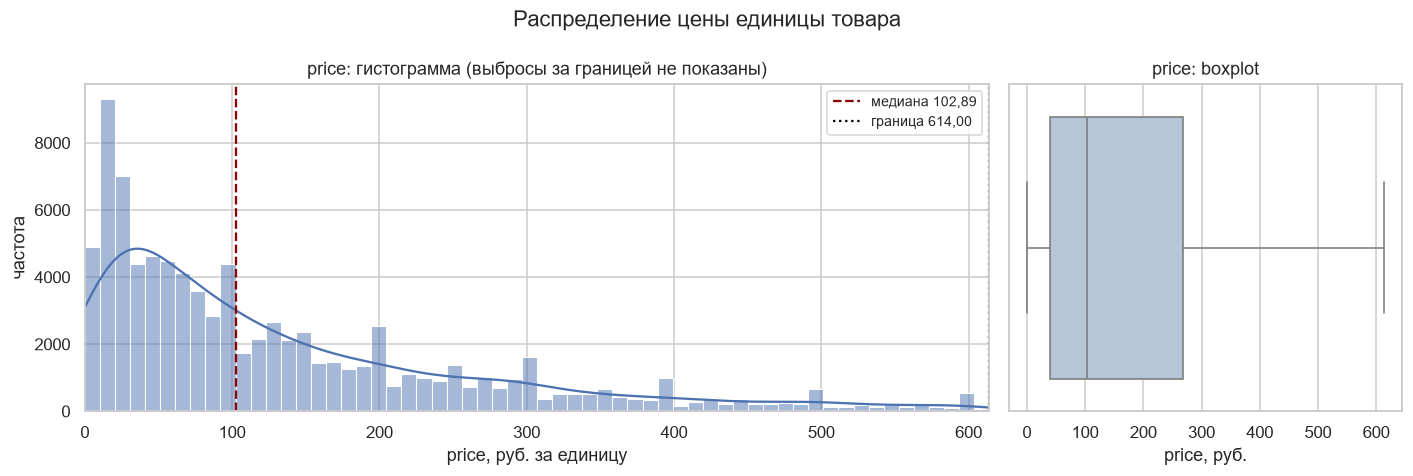

In [13]:
def iqr_bounds(series: pd.Series, k: float = 1.5) -> dict:
    """Квартили, IQR и границы выбросов по правилу Q ± k·IQR."""
    q1, median, q3 = series.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    return {
        "min": series.min(),
        "q1": q1,
        "median": median,
        "q3": q3,
        "max": series.max(),
        "iqr": iqr,
        "lower": q1 - k * iqr,
        "upper": q3 + k * iqr,
    }


price = df["price"]
bounds = iqr_bounds(price)

print("Описательная статистика price:")
for title, value in [
    ("минимум", bounds["min"]),
    ("Q1 (25 %)", bounds["q1"]),
    ("медиана (50 %)", bounds["median"]),
    ("Q3 (75 %)", bounds["q3"]),
    ("максимум", bounds["max"]),
    ("IQR", bounds["iqr"]),
    ("lower_bound", bounds["lower"]),
    ("upper_bound", bounds["upper"]),
]:
    print(f"  {title:<16} {fmt_money(value)}")

is_outlier = (price < bounds["lower"]) | (price > bounds["upper"])
print(
    f"\nВыбросов: {fmt_int(int(is_outlier.sum()))} "
    f"({fmt_pct(is_outlier.mean() * 100)} строк), "
    f"они дают {fmt_pct(df.loc[is_outlier, 'amount'].sum() / df['amount'].sum() * 100)} выручки"
)

show_cols = ["tr_date", "tcode", "client", "item", "item_group", "quantity", "amount", "price"]
print("\n10 самых дорогих строк:")
display(df.nlargest(10, "price")[show_cols])
print("10 самых дешёвых строк:")
display(df.nsmallest(10, "price")[show_cols])

fig, (ax_hist, ax_box) = plt.subplots(
    1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [2.3, 1]}
)
plot_histogram(ax_hist, price, xlim=bounds["upper"], xlabel="price, руб. за единицу")
ax_hist.axvline(bounds["median"], color="darkred", linestyle="--", label=f"медиана {fmt_money(bounds['median'])}")
ax_hist.axvline(bounds["upper"], color="black", linestyle=":", label=f"граница {fmt_money(bounds['upper'])}")
ax_hist.set_title("price: гистограмма (выбросы за границей не показаны)")
ax_hist.legend(fontsize=9)

sns.boxplot(x=price, ax=ax_box, showfliers=False, color="lightsteelblue")
ax_box.set_title("price: boxplot")
ax_box.set_xlabel("price, руб.")
fig.suptitle("Распределение цены единицы товара")
fig.tight_layout()
plt.show()


## Шаг 12. ABC-анализ товаров по сумме продаж

**Промпт к AI-ассистенту:**

> Выполни ABC-анализ товаров по сумме продаж: 1. Сгруппируй данные по item и
> рассчитай сумму продаж каждого товара 2. Отсортируй товары по сумме продаж в
> убывающем порядке 3. Рассчитай накопительный процент (cumulative %) для
> каждого товара: - Общая сумма всех продаж = total_sum - Для каждого товара:
> cumulative_sum / total_sum * 100 4. На основе накопительного процента
> распредели товары на группы: - Группа A: cumulative % <= 80% - Группа B:
> cumulative % > 80% and <= 95% - Группа C: cumulative % > 95% 5. Выведи
> количество товаров в каждой группе и примеры товаров из каждой группы

Главное изменение версии 2: ABC и XYZ — это два среза одной таблицы по
товарам, поэтому считаем её **один раз** функцией `abc_xyz_analysis`, а шаги
12–14 только показывают нужные колонки.

In [14]:
def abc_xyz_analysis(
    df: pd.DataFrame,
    threshold_a: float = ABC_THRESHOLD_A,
    threshold_b: float = ABC_THRESHOLD_B,
    with_zeros: bool = False,
) -> pd.DataFrame:
    """ABC по сумме продаж + XYZ по коэффициенту вариации количества.

    Возвращает таблицу по товарам: item, total_quantity, total_amount,
    cumulative_pct, abc_group, months, cv, xyz_group, abc_xyz.
    with_zeros=True считает месяцы без продаж нулями при расчёте CV.
    """
    if not 0 < threshold_a <= threshold_b <= 100:
        raise ValueError(f"Нужно 0 < a <= b <= 100, получено a={threshold_a}, b={threshold_b}")

    items = (
        df.groupby("item", observed=True, as_index=False)
        .agg(
            total_quantity=("quantity", "sum"),
            total_amount=("amount", "sum"),
        )
        .sort_values("total_amount", ascending=False)
        .reset_index(drop=True)
    )
    # item в category удобен для groupby, но для merge по товарам берём object
    items["item"] = items["item"].astype(object)

    total_sum = items["total_amount"].sum()
    if total_sum <= 0:
        raise ValueError("Сумма продаж равна нулю — ABC-анализ невозможен")

    items["cumulative_sum"] = items["total_amount"].cumsum()
    items["cumulative_pct"] = items["cumulative_sum"] / total_sum * 100
    items["abc_group"] = np.select(
        [items["cumulative_pct"] <= threshold_a, items["cumulative_pct"] <= threshold_b],
        ["A", "B"],
        default="C",
    )

    monthly = (
        df.assign(month=df["tr_date"].dt.to_period("M"))
        .groupby(["item", "month"], observed=True, as_index=False)["quantity"]
        .sum()
    )
    pivot = monthly.pivot(index="item", columns="month", values="quantity").fillna(0)
    series = pivot if with_zeros else pivot.replace(0, np.nan)

    cv_table = pd.DataFrame(
        {
            "item": pivot.index.astype(object),
            "months": (pivot > 0).sum(axis=1).values,
            "periods": pivot.shape[1],
            "mean_month": series.mean(axis=1).values,
            "std_month": series.std(axis=1, ddof=1).values,
            "cv": (series.std(axis=1, ddof=1) / series.mean(axis=1) * 100).values,
        }
    )
    items = items.merge(cv_table, on="item", how="left")

    items["xyz_group"] = np.select(
        [items["cv"] < XYZ_CV_X, items["cv"] <= XYZ_CV_Y],
        ["X", "Y"],
        default="Z",   # в том числе товары с одним активным месяцем (CV = NaN)
    )
    items["abc_xyz"] = items["abc_group"] + items["xyz_group"]
    return items


items_full = abc_xyz_analysis(df)

print("ABC-анализ (та же таблица, что используется в шагах 13–14):")
for group in ["A", "B", "C"]:
    part = items_full[items_full["abc_group"] == group]
    print(
        f"  {group}: {fmt_int(len(part))} товаров "
        f"({fmt_pct(len(part) / len(items_full) * 100)} ассортимента), "
        f"{fmt_pct(part['total_amount'].sum() / items_full['total_amount'].sum() * 100)} выручки"
    )

print("\nПримеры группы A:")
display(items_full[items_full["abc_group"] == "A"].head(5)[
    ["item", "total_quantity", "total_amount", "cumulative_pct"]
])
print("Примеры группы C (хвост):")
display(items_full[items_full["abc_group"] == "C"].tail(5)[
    ["item", "total_quantity", "total_amount", "cumulative_pct"]
])


ABC-анализ (та же таблица, что используется в шагах 13–14):
  A: 5 353 товаров (17,51 % ассортимента), 80,00 % выручки
  B: 8 234 товаров (26,94 % ассортимента), 15,00 % выручки
  C: 16 979 товаров (55,55 % ассортимента), 5,00 % выручки

Примеры группы A:
       item  total_quantity  total_amount  cumulative_pct
0  sku26161           18902       5373638        0.854847
1  sku18199            7250       3951361        1.483435
2  sku21947           15304       3918570        2.106808
3  sku28128            7705       3027786        2.588473
4   sku8342            3512       2113158        2.924637
Примеры группы C (хвост):
           item  total_quantity  total_amount  cumulative_pct
30561  sku20003               2             2       99.999999
30562  sku25319               1             1      100.000000
30563  sku24554               1             1      100.000000
30564  sku29884               1             1      100.000000
30565  sku22563               1             1      100.00000

## Шаг 13. XYZ-анализ товаров по количеству

**Промпт к AI-ассистенту:**

> Дополни XYZ-анализ товаров (по количеству): Используй для расчета
> коэффициент вариации = std / mean * 100 3. На основе коэффициента вариации
> распредели товары: - Группа X: CV < 15% - Группа Y: 15% <= CV <= 25% -
> Группа Z: CV > 25% 4. Выведи количество товаров в каждой группе

XYZ уже посчитан в шаге 12 — здесь только срез и проверка альтернативного
варианта (`with_zeros=True`): если считать месяцы без продаж нулями, в Z
попадают все товары, поэтому рабочий вариант — CV по активным месяцам.

In [15]:
print("Количество товаров по группам (CV по активным месяцам):")
for group in ["X", "Y", "Z"]:
    part = items_full[items_full["xyz_group"] == group]
    median_cv = fmt_pct(part["cv"].median()) if len(part) else "—"
    print(
        f"  {group}: {fmt_int(len(part))} товаров "
        f"({fmt_pct(len(part) / len(items_full) * 100)} ассортимента), "
        f"медианный CV {median_cv}"
    )

periods = df["tr_date"].dt.to_period("M").nunique()
print(f"\nПериодов (месяцев) в данных: {periods}; максимум активных месяцев у товара: {int(items_full['months'].max())}")

items_zeros = abc_xyz_analysis(df, with_zeros=True)
share_z = (items_zeros["xyz_group"] == "Z").mean() * 100
print(
    f"Альтернатива с нулями: в Z попадает {fmt_pct(share_z)} товаров "
    f"(медианный CV {fmt_pct(items_zeros['cv'].median())}) — поэтому используем активные месяцы"
)


Количество товаров по группам (CV по активным месяцам):
  X: 3 122 товаров (10,21 % ассортимента), медианный CV 0,00 %
  Y: 263 товаров (0,86 % ассортимента), медианный CV 21,08 %
  Z: 27 181 товаров (88,93 % ассортимента), медианный CV 66,11 %

Периодов (месяцев) в данных: 26; максимум активных месяцев у товара: 26
Альтернатива с нулями: в Z попадает 100,00 % товаров (медианный CV 228,73 %) — поэтому используем активные месяцы


## Шаг 14. Матрица ABC × XYZ

**Промпт к AI-ассистенту:**

> создай перекрестную таблицу (pivot table) ABC группа x XYZ группа для
> матрицы ABC-XYZ

`pivot_table` сразу с `margins=True`, поэтому в таблице есть итоговые
строка и столбец — раньше их приходилось считать вручную.

Количество товаров (ABC × XYZ):
xyz_group     X    Y      Z  Итого
abc_group                         
A           265   36   5052   5353
B           811   80   7343   8234
C          2046  147  14786  16979
Итого      3122  263  27181  30566
Выручка, руб.:
xyz_group         X        Y          Z      Итого
abc_group                                         
A          12102682  1649698  489122717  502875097
B           9101036   957939   84240160   94299135
C           3372027   268770   27793312   31434109
Итого      24575745  2876407  601156189  628608341
Доля выручки, %:
xyz_group     X     Y      Z  Итого
abc_group                          
A          1.93  0.26  77.81   80.0
B          1.45  0.15  13.40   15.0
C          0.54  0.04   4.42    5.0
Итого      3.91  0.46  95.63  100.0


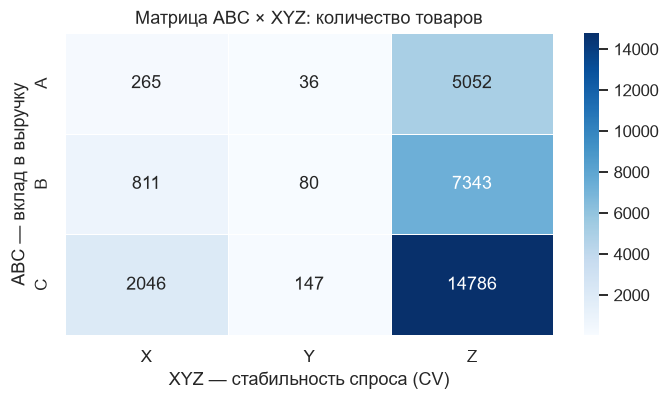

In [16]:
def abc_xyz_matrix(per_item: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Три среза матрицы ABC × XYZ: количество товаров, выручка, доля выручки."""
    counts = pd.pivot_table(
        per_item,
        index="abc_group",
        columns="xyz_group",
        values="item",
        aggfunc="count",
        fill_value=0,
        margins=True,
        margins_name="Итого",
    )
    revenue = pd.pivot_table(
        per_item,
        index="abc_group",
        columns="xyz_group",
        values="total_amount",
        aggfunc="sum",
        fill_value=0,
        margins=True,
        margins_name="Итого",
    )
    share = (revenue / per_item["total_amount"].sum() * 100).round(2)
    return {"counts": counts, "revenue": revenue, "share": share}


matrix = matrix_slices = abc_xyz_matrix(items_full)

print("Количество товаров (ABC × XYZ):")
display(matrix["counts"])
print("Выручка, руб.:")
display(matrix["revenue"])
print("Доля выручки, %:")
display(matrix["share"])

abc_xyz_matrix_flat = (
    items_full.groupby(["abc_group", "xyz_group"], as_index=False)
    .agg(tovary=("item", "count"), revenue=("total_amount", "sum"))
    .rename(columns={"tovary": "товаров", "revenue": "выручка"})
)
abc_xyz_matrix_flat["доля_выручки_%"] = (
    abc_xyz_matrix_flat["выручка"] / abc_xyz_matrix_flat["выручка"].sum() * 100
).round(4)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
sns.heatmap(matrix["counts"].iloc[:-1, :-1], annot=True, fmt="d", cmap="Blues",
            linewidths=0.6, ax=ax)
ax.set_title("Матрица ABC × XYZ: количество товаров")
ax.set_xlabel("XYZ — стабильность спроса (CV)")
ax.set_ylabel("ABC — вклад в выручку")
fig.tight_layout()
plt.show()


## Шаг 15. Сравнение периодов

**Промпт к AI-ассистенту:**

> 1. Создай функцию abc_xyz_analysis(df, abc_threshold_a=80,
> abc_threshold_b=95): - Которая выполняет весь ABC-XYZ анализ из предыдущих
> инструкций - Параметры позволяют менять границы групп A и B 2. Отфильтруй
> исходный DataFrame за последние 6 месяцев (с 01.05.2019 по 31.10.2019)
> 3. Запусти функцию на отфильтрованных данных: abc_xyz_analysis(df_last_6m)
> 4. Сравни результаты за весь период и за последние 6 месяцев: - Сколько
> товаров перешло из группы в группу? - Какие товары стали важнее? Какие -
> менее важны? Используй только товары, которые есть в обоих периодах

Функция та же, что в шаге 12, — меняется только входной `DataFrame`.
Сравнение идёт по пересечению товаров, поэтому товары, пропавшие из продаж,
не считаются «упавшими».

In [17]:
df_period = filter_period(df, PERIOD_START, PERIOD_END)
items_period = abc_xyz_analysis(df_period)

print(f"Товаров: весь период — {fmt_int(len(items_full))}, "
      f"6 месяцев — {fmt_int(len(items_period))}")

common = items_full.merge(items_period, on="item", suffixes=("_full", "_6m"))
check(len(common) <= min(len(items_full), len(items_period)), "пересечение больше выборок")
print(f"Товаров в обоих периодах: {fmt_int(len(common))}")

abc_moves = pd.crosstab(
    common["abc_group_full"], common["abc_group_6m"], margins=True, margins_name="Итого"
)
xyz_moves = pd.crosstab(
    common["xyz_group_full"], common["xyz_group_6m"], margins=True, margins_name="Итого"
)
print("\nПереходы ABC (строки — весь период, столбцы — 6 месяцев):")
display(abc_moves)
print("Переходы XYZ:")
display(xyz_moves)

moved_abc = int((common["abc_group_full"] != common["abc_group_6m"]).sum())
moved_xyz = int((common["xyz_group_full"] != common["xyz_group_6m"]).sum())
print(
    f"Сменили ABC-группу: {fmt_int(moved_abc)} ({fmt_pct(moved_abc / len(common) * 100)}), "
    f"XYZ-группу: {fmt_int(moved_xyz)} ({fmt_pct(moved_xyz / len(common) * 100)})"
)

common["share_full"] = common["total_amount_full"] / common["total_amount_full"].sum() * 100
common["share_6m"] = common["total_amount_6m"] / common["total_amount_6m"].sum() * 100
common["share_delta_pp"] = common["share_6m"] - common["share_full"]

cols = ["item", "abc_group_full", "abc_group_6m", "share_full", "share_6m", "share_delta_pp"]
print("\nСтали важнее (рост доли выручки, п.п.):")
display(common.nlargest(5, "share_delta_pp")[cols].round(3).reset_index(drop=True))
print("Стали менее важны:")
display(common.nsmallest(5, "share_delta_pp")[cols].round(3).reset_index(drop=True))


Товаров: весь период — 30 566, 6 месяцев — 21 767
Товаров в обоих периодах: 21 767

Переходы ABC (строки — весь период, столбцы — 6 месяцев):
abc_group_6m       A     B      C  Итого
abc_group_full                          
A               3341  1007    173   4521
B                515  3944   1776   6235
C                  0   831  10180  11011
Итого           3856  5782  12129  21767
Переходы XYZ:
xyz_group_6m       X    Y      Z  Итого
xyz_group_full                         
X               1007    1    913   1921
Y                  7   83     71    161
Z               1206  529  17950  19685
Итого           2220  613  18934  21767
Сменили ABC-группу: 4 302 (19,76 %), XYZ-группу: 2 727 (12,53 %)

Стали важнее (рост доли выручки, п.п.):
       item abc_group_full abc_group_6m  share_full  share_6m  share_delta_pp
0  sku22208              A            A       0.211     0.386           0.175
1   sku3243              A            A       0.153     0.287           0.133
2  sku23883       

## Шаг 16. Сохранение результатов в CSV

**Промпт к AI-ассистенту:**

> Сохрани результаты анализа в CSV файлы: Результаты ТОП-5 товаров →
> 'top_5_products.csv' 2. Статистику по клиентам → 'client_statistics.csv'
> ABC-анализ товаров → 'abc_analysis.csv' XYZ-анализ товаров →
> 'xyz_analysis.csv' Матрицу ABC-XYZ → 'abc_xyz_matrix.csv' Данные за
> последние 6 месяцев → 'last_6_months_data.csv'. Используй method='w',
> index=False для сохранения без индекса Проверь, что файлы успешно созданы,
> выведи первые 5 строк каждого файла

`save_csv` пишет `mode="w"`, `index=False` (как требует задание), добавляет
`utf-8-sig` для Excel и перечитывает файл, сверяя колонки.

In [18]:
def save_csv(df: pd.DataFrame, name: str, folder: str | Path = ".") -> Path:
    """Пишет таблицу в CSV без индекса и проверяет, что файл читается обратно."""
    file_path = Path(folder) / name
    file_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(file_path, mode="w", index=False, encoding="utf-8-sig")

    check(file_path.exists(), f"файл {name} не создан")
    check(list(pd.read_csv(file_path, nrows=1).columns) == list(df.columns),
          f"{name}: колонки после записи не совпадают")
    return file_path


files = {
    "top_5_products.csv": top_5_products,
    "client_statistics.csv": client_stats,
    "abc_analysis.csv": items_full[
        ["item", "total_quantity", "total_amount", "cumulative_sum", "cumulative_pct", "abc_group"]
    ],
    "xyz_analysis.csv": items_full[
        ["item", "months", "periods", "mean_month", "std_month", "cv", "total_quantity", "xyz_group"]
    ],
    "abc_xyz_matrix.csv": abc_xyz_matrix_flat,
    "last_6_months_data.csv": df_last_6m,
}

print("Сохранение:")
for name, table in files.items():
    path = save_csv(table, name)
    print(f"  {name:<26} {fmt_int(len(table)):>9} строк  {path.stat().st_size / 1024:>8.1f} КБ")

print("\nПервые 5 строк каждого файла:")
for name in files:
    print(f"\n--- {name} ---")
    display(pd.read_csv(name, nrows=5))


Сохранение:
  top_5_products.csv                 5 строк       0.1 КБ
  client_statistics.csv         42 746 строк     961.5 КБ
  abc_analysis.csv              30 566 строк    1414.1 КБ
  xyz_analysis.csv              30 566 строк    1714.4 КБ
  abc_xyz_matrix.csv                 9 строк       0.3 КБ
  last_6_months_data.csv       347 737 строк   28786.4 КБ

Первые 5 строк каждого файла:

--- top_5_products.csv ---
       item  quantity   amount
0  sku26161     18902  5373638
1  sku18199      7250  3951361
2  sku21947     15304  3918570
3  sku28128      7705  3027786
4   sku8342      3512  2113158

--- client_statistics.csv ---
        client  total_quantity  total_amount  visit_dates
0  client29182            3434       3887309          107
1  client15654            5457       1443255          174
2   client8778            1617        986618           17
3   client1704            1187        636101           23
4  client33032            1255        537397           74

--- abc_analysi

## Итоги

* **Данные**: 1 008 688 транзакций, 30 566 товаров, 42 746 клиентов; пропусков
  нет, одна строка с `quantity = 0` удалена, дата приведена к `datetime`.
* **Клиенты**: 30,1 % приходят один раз и дают 7,2 % выручки; 9 клиентов-
  экстремумов (≥ 2 000 шт. или ≥ 500 000 руб.) дают 1,46 % выручки.
* **Товары**: ТОП-5 — 2,92 % выручки; ABC — 17,5 % ассортимента дают 80 %
  денег; XYZ — 88,9 % товаров в группе Z.
* **Матрица**: 77,8 % выручки в ячейке AZ — много и нестабильно; там нужны
  прогноз и страховой запас.
* **Код**: все расчёты в функциях с проверками, ABC-XYZ считается один раз,
  константы вынесены в конфиг, экспорт CSV проверяется обратным чтением.
